# 6. A/B compartment calling

`uchrom.strc.comp.call_compartments_axes_pc` is a GPU-accelerated
reimplementation of the ArcFISH `ABCaller.by_axes_pc`.  The idea:

- Turn each axis' normalised variance matrix into a pseudo-contact
  matrix ``K = exp(-var)``.
- Take the **second-largest eigenvector** of each axis' ``K``.  The
  first captures the overall distance-decay trend; the second captures
  compartment-scale alternation.
- Weight the three per-axis PC2's by the ArcFISH axis weights, stack
  them as a 3-feature vector per bin, and run ``KMeans(n=2)``.
- Assign A/B so that the cluster with smaller mean intra-distance is
  the more compact one (A by convention).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uchrom import ChromData
from uchrom.strc.comp import call_compartments_axes_pc, CompartmentCallerParams
from uchrom.fea import mean_distance_matrix
from uchrom.pl import plot_distance_matrix


## Load example data

Uses the Takei et al. 2021 Nature mESC chromatin-tracing dataset (4DN `4DNFIHF3JCBY`); auto-downloaded from the public 4DN S3 bucket on first run, cached under `example-data/`.


In [2]:
from pathlib import Path

TAKEI_URL = (
    'https://4dn-open-data-public.s3.amazonaws.com/fourfront-webprod/'
    'wfoutput/e699334e-fb34-4a0e-8ef6-670b2099831a/4DNFIHF3JCBY.csv'
)

def _repo_root() -> Path:
    # Walk up until we find the repo marker (pyproject.toml); fall back to
    # cwd if nothing matches.  Avoid matching on ``example-data/`` alone —
    # prior notebook runs may have synthesised a ``tutorials/example-data/``.
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'pyproject.toml').exists():
            return p
    return Path.cwd()

def find_fofct() -> str:
    root = _repo_root()
    candidates = [
        root / 'example-data' / '4DNFIHF3JCBY.csv',
        Path.home() / 'Downloads' / 'ArcFISH_data' / '4DNFIHF3JCBY.csv',
        Path.home() / 'Downloads' / 'ArcFISH_data' / '4DNFIHF3JCBY.h5cd',
        Path.home() / 'Downloads' / '4DNFIHF3JCBY.csv',
    ]
    for c in candidates:
        if c.exists():
            return str(c)
    cand = root / 'example-data' / 'fofct_core.csv'
    if cand.exists():
        return str(cand)
    dest = root / 'example-data' / '4DNFIHF3JCBY.csv'
    dest.parent.mkdir(parents=True, exist_ok=True)
    print(f'[data] downloading Takei 2021 (~22 MB) → {dest}')
    import urllib.request
    tmp = dest.with_suffix(dest.suffix + '.part')
    urllib.request.urlretrieve(TAKEI_URL, tmp)
    tmp.rename(dest)
    return str(dest)

FOFCT = find_fofct()
print(FOFCT)
cd = ChromData.read(FOFCT) if FOFCT.endswith(".h5cd") else ChromData.from_fofct(FOFCT)
cd


/Users/weizexu/Projects/U-Chrom/example-data/4DNFIHF3JCBY.csv


ChromData: n_spots=316995, n_traces=8285, n_cells=201
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']

## Run the compartment caller


In [3]:
chrom = cd.spots['chrom'].astype(str).iloc[0]
comps = call_compartments_axes_pc(
    cd, chrom=chrom,
    params=CompartmentCallerParams(min_bins=2),
    device='auto', verbose=True,
)
print('compartment counts:')
print(comps['compartment'].value_counts())
comps.head(10)


[comp/chr1] variance cube + normalise...


[comp/chr1] axis weights: [0.323 0.324 0.353]
[comp/chr1] KMeans on 60 bins × 3 features
compartment counts:
compartment
A    36
B    24
Name: count, dtype: int64


,chrom,start,end,bin_index,cluster,compartment,pc2
0,chr1,135600000,135625000,0,0,A,0.073222
1,chr1,135625000,135650000,1,0,A,0.000651
2,chr1,135650000,135675000,2,0,A,0.028382
3,chr1,135675000,135700000,3,0,A,-0.001289
4,chr1,135700000,135725000,4,0,A,-0.018905
5,chr1,135725000,135750000,5,0,A,-0.022017
6,chr1,135750000,135775000,6,0,A,-0.041481
7,chr1,135775000,135800000,7,0,A,0.033119
8,chr1,135800000,135825000,8,0,A,0.024442
9,chr1,135825000,135850000,9,0,A,-0.008073


## Compartment track

The weighted PC2 track alternates along the chromosome; A / B labels come from KMeans.


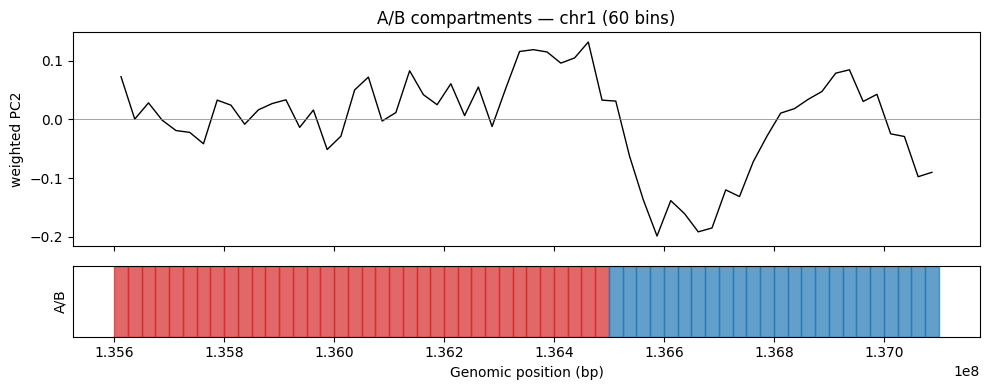

In [4]:
fig, (ax_track, ax_label) = plt.subplots(
    2, 1, figsize=(10, 4), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]},
)

mid_bp = (comps['start'] + comps['end']) / 2
ax_track.plot(mid_bp, comps['pc2'], 'k-', lw=1)
ax_track.axhline(0, color='grey', lw=0.5)
ax_track.set_ylabel('weighted PC2')
ax_track.set_title(f'A/B compartments — {chrom} ({len(comps)} bins)')

colors = {'A': 'tab:red', 'B': 'tab:blue'}
for lab, sub in comps.groupby('compartment'):
    for _, r in sub.iterrows():
        ax_label.axvspan(r['start'], r['end'], color=colors[lab], alpha=0.7)
ax_label.set_yticks([])
ax_label.set_xlabel('Genomic position (bp)')
ax_label.set_ylabel('A/B')
plt.tight_layout()
plt.show()


## Compartments on the distance matrix

Visualising per-bin A/B labels next to the population-mean distance matrix makes the compartment pattern clear: A-A and B-B pairs are usually closer than A-B pairs.


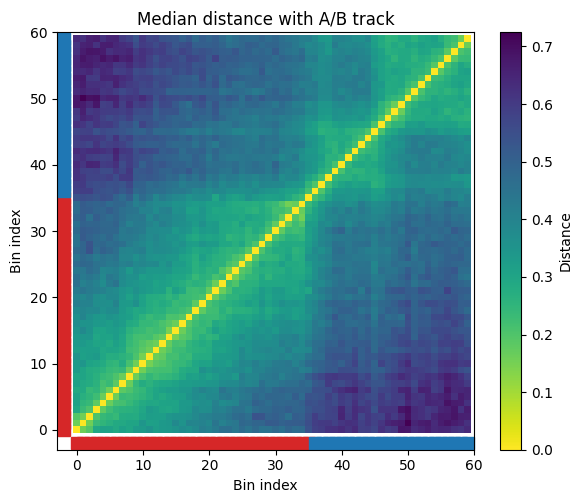

In [5]:
df = cd.get_chrom(chrom).to_dataframe()
dmat, bin_ids, _ = mean_distance_matrix(df, chrom=chrom)
fig = plot_distance_matrix(dmat, title=f'Median distance with A/B track')

ax = fig.axes[0]
# Colour the diagonal edge by compartment label
B = len(bin_ids)
for i in range(B):
    lab = comps.iloc[i]['compartment']
    ax.plot(i, -2, 's', ms=8, color=colors[lab], clip_on=False)
    ax.plot(-2, i, 's', ms=8, color=colors[lab], clip_on=False)
ax.set_xlim(-3, B)
ax.set_ylim(-3, B)
plt.show()


## Notes

- The A/B assignment here is a convention (smaller mean intra-distance
  → A).  With a gene-density annotation you would pick whichever
  cluster has higher TSS density as A — this library does not ship
  that integration.
- ``n_clusters`` can be > 2 if you want to explore sub-compartment
  structure (A1 / A2 / B1 / B2).  The naming in the output DataFrame
  will no longer be ``{A, B}``.
- Like the loop and TAD callers, this caller shares the
  ``filter_normalize`` preprocessing step with the other ArcFISH-style
  routines.
